# Microcontroller Inventory Simulator
Caden Hill

An industrial manufacturer buys a 32-bit microcontroller (MCU) from one distributor and puts it on the control boards for its motor drives. Daily usage moves around, the distributor's lead time moves around, and if the plant runs out of MCUs the board line stops. This notebook works out how many MCUs to keep on hand and how many to order at a time. It also looks at what the distributor's unreliable lead times are costing and whether a 3% discount for ordering full reels in bigger batches is worth taking.

I start with the textbook formulas and then check them with a Monte Carlo simulation. All the numbers are made up for illustration.

In [1]:
import pandas as pd, numpy as np
from IPython.display import Image, display
import inventory_sim as sim

item = sim.Item()
pd.DataFrame({
    "Parameter": ["Part", "Avg daily demand", "Demand std dev", "Avg lead time", "Lead time std dev",
                  "Unit cost", "Holding rate", "Cost per PO", "Shortage cost"],
    "Value": [item.name, f"{item.demand_mean:,.0f} MCUs", f"{item.demand_sd:,.0f} MCUs", f"{item.lead_mean:.0f} days",
              f"{item.lead_sd:.0f} days", f"${item.unit_cost:.2f}", f"{item.holding_rate:.0%} per year",
              f"${item.order_cost:.0f}", f"${item.shortage_cost:.0f} per MCU short"],
}).set_index("Parameter")

,Value
Parameter,
Part,"32-bit microcontroller, 2,500 per reel"
Avg daily demand,"1,200 MCUs"
Demand std dev,360 MCUs
Avg lead time,21 days
Lead time std dev,6 days
Unit cost,$6.50
Holding rate,25% per year
Cost per PO,$400
Shortage cost,$15 per MCU short


## Baseline with the textbook formulas
EOQ = sqrt(2DS / H)

Since both demand and lead time vary, the std dev of demand during the lead time is
sigma_DLT = sqrt(L * sd_d^2 + d^2 * sd_L^2)

Reorder point = d * L + z * sigma_DLT, where z comes from the target cycle service level (the chance of getting through a replenishment cycle without running out).

In [2]:
q = sim.eoq(item)
print(f"Annual demand: {item.annual_demand:,.0f} MCUs (${item.annual_demand*item.unit_cost:,.0f} a year)")
print(f"EOQ: {q:,.0f} MCUs per order (~{item.annual_demand/q:.0f} orders a year)")
print(f"sigma(DLT): {sim.sigma_dlt(item):,.0f} MCUs")
lt_share = item.demand_mean**2 * item.lead_sd**2 / sim.sigma_dlt(item)**2
print(f"Share of that variance coming from lead time: {lt_share:.0%}")
pd.DataFrame([{"Target CSL": f"{c:.1%}", "z": round(sim.norm.ppf(c), 2),
               "Safety stock (MCUs)": f"{sim.safety_stock(item, c):,.0f}",
               "Reorder point (MCUs)": f"{sim.reorder_point(item, c):,.0f}",
               "Safety stock value": f"${sim.safety_stock(item, c)*item.unit_cost:,.0f}"}
              for c in [0.95, 0.98, 0.99, 0.998, 0.999]]).set_index("Target CSL")

Annual demand: 438,000 MCUs ($2,847,000 a year)
EOQ: 14,684 MCUs per order (~30 orders a year)
sigma(DLT): 7,387 MCUs
Share of that variance coming from lead time: 95%


,z,Safety stock (MCUs),Reorder point (MCUs),Safety stock value
Target CSL,,,,
95.0%,1.64,"12,150","37,350","$78,974"
98.0%,2.05,"15,170","40,370","$98,606"
99.0%,2.33,"17,184","42,384","$111,694"
99.8%,2.88,"21,260","46,460","$138,189"
99.9%,3.09,"22,826","48,026","$148,371"


About 95% of the uncertainty comes from the distributor's lead time and only a small part comes from demand. So the real problem here is the supplier, and forecasting better wouldn't help much.

## Simulation
The formula assumes demand during the lead time follows a normal distribution, but real lead times skew late. A shipment can show up a week late but it can't show up a week early. So I simulated it:
- daily demand and each order's lead time come from gamma distributions with the same averages and std devs as above
- the distributor ships POs in the order they were placed, so one late PO also holds up the next one
- inventory gets checked every day, and when inventory position (on hand plus on order) hits the reorder point the plant orders Q
- if the plant runs out, that demand is lost and charged at the shortage cost
- each policy runs for 400 separate years after a 90 day warm-up

In [3]:
res = sim.main(".")   # runs everything and writes results/ and charts/
frontier = res["frontier"]
show = frontier[["target_csl", "safety_stock", "cycle_service_level", "fill_rate",
                 "holding_cost", "ordering_cost", "shortage_cost", "total_cost"]].copy()
show.columns = ["Target CSL", "Safety stock", "Simulated CSL", "Fill rate", "Holding $", "Ordering $", "Shortage $", "Total $"]
show.style.format({"Target CSL": "{:.2%}", "Safety stock": "{:,.0f}", "Simulated CSL": "{:.1%}", "Fill rate": "{:.2%}",
                   "Holding $": "${:,.0f}", "Ordering $": "${:,.0f}", "Shortage $": "${:,.0f}", "Total $": "${:,.0f}"}).hide(axis="index")

Item: 32-bit microcontroller, 2,500 per reel
Annual demand 438,000 MCUs | EOQ 14,684 | sigma(DLT) 7,386.6



Service level sweep (400 sim years each):
 target_csl  safety_stock  cycle_service_level  fill_rate  holding_cost  ordering_cost  shortage_cost  total_cost
      0.800      6216.705                0.850      0.952     23786.885        11384.0     312671.475  347842.360
      0.850      7655.701                0.882      0.963     25492.213        11509.0     242960.925  279962.138
      0.900      9466.286                0.915      0.973     27848.850        11635.0     177185.438  216669.288
      0.930     10901.052                0.934      0.980     29806.876        11704.0     133368.150  174879.026
      0.950     12149.847                0.950      0.985     31637.164        11774.0      99750.375  143161.539
      0.970     13892.637                0.964      0.989     34193.752        11823.0      73188.638  119205.390
      0.980     15170.186                0.972      0.992     36150.514        11862.0      54813.638  102826.152
      0.990     17183.760                0.98

Target CSL,Safety stock,Simulated CSL,Fill rate,Holding $,Ordering $,Shortage $,Total $
80.00%,"6,217",85.0%,95.25%,"$23,787","$11,384","$312,671","$347,842"
85.00%,"7,656",88.2%,96.30%,"$25,492","$11,509","$242,961","$279,962"
90.00%,"9,466",91.5%,97.31%,"$27,849","$11,635","$177,185","$216,669"
93.00%,"10,901",93.4%,97.97%,"$29,807","$11,704","$133,368","$174,879"
95.00%,"12,150",95.0%,98.48%,"$31,637","$11,774","$99,750","$143,162"
97.00%,"13,893",96.4%,98.89%,"$34,194","$11,823","$73,189","$119,205"
98.00%,"15,170",97.2%,99.17%,"$36,151","$11,862","$54,814","$102,826"
99.00%,"17,184",98.2%,99.50%,"$39,305","$11,908","$32,870","$84,083"
99.50%,"19,027",97.9%,99.65%,"$42,316","$11,916","$23,185","$77,417"
99.80%,"21,260",99.3%,99.80%,"$45,871","$11,932","$13,182","$70,985"


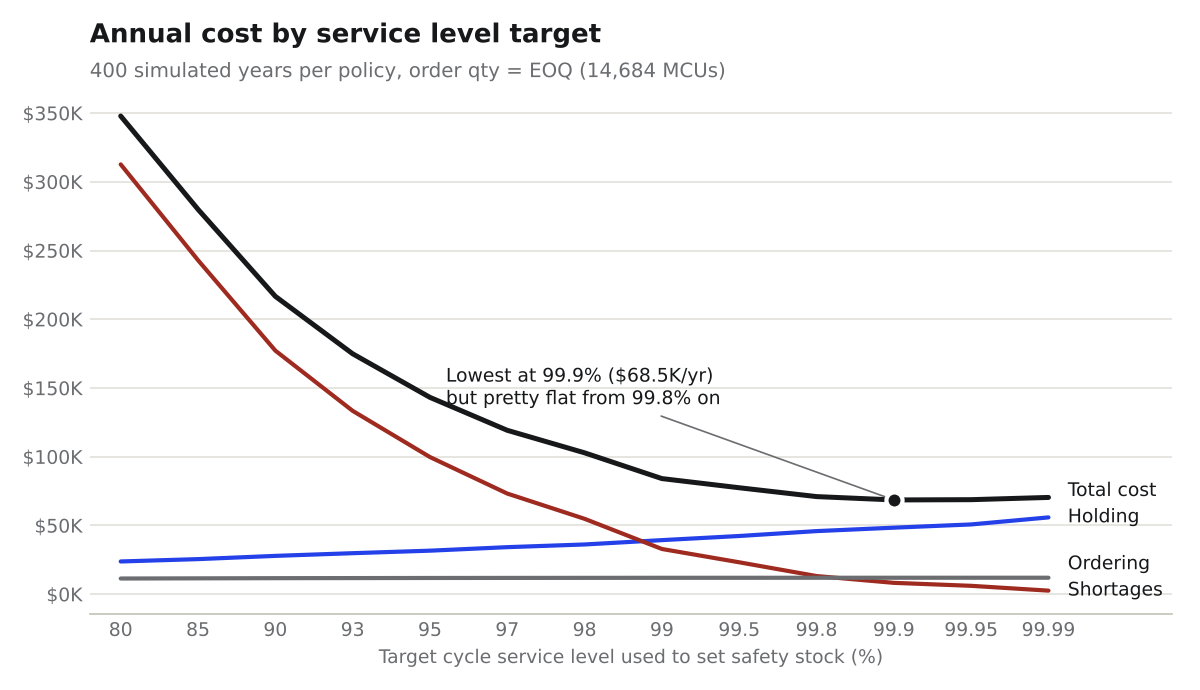

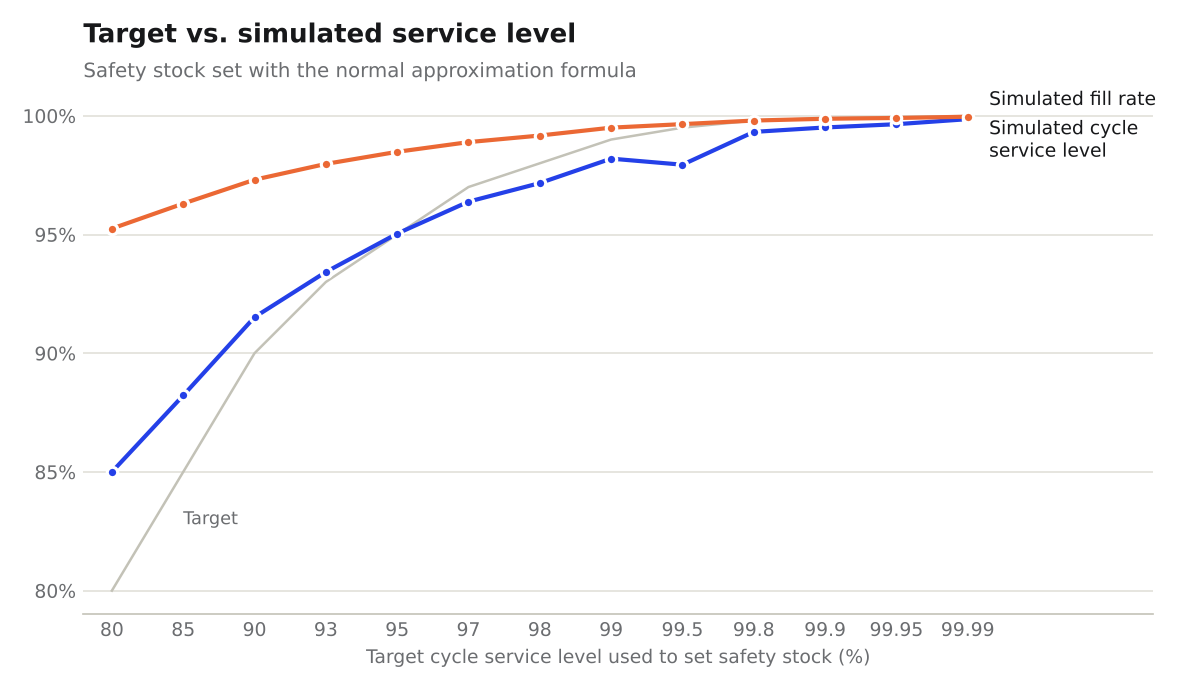

In [4]:
display(Image("charts/1_cost_vs_service_level.png", width=760))
display(Image("charts/2_target_vs_achieved_service.png", width=760))

In [5]:
best = res["best"]
row99 = frontier.loc[(frontier.target_csl - 0.99).abs().idxmin()]
row95 = frontier.loc[(frontier.target_csl - 0.95).abs().idxmin()]
print(f"Cheapest target: {best.target_csl:.1%} -> ${best.total_cost:,.0f}/yr")
print(f"Running at 99% costs ${row99.total_cost - best.total_cost:,.0f}/yr more, and 95% costs ${row95.total_cost - best.total_cost:,.0f}/yr more")
planned = 1 - best.target_csl; actual = 1 - best.cycle_service_level
print(f"A {best.target_csl:.1%} target actually gets {best.cycle_service_level:.1%}, so about {actual/planned:.0f}x as many stockout cycles as planned")

Cheapest target: 99.9% -> $68,545/yr
Running at 99% costs $15,538/yr more, and 95% costs $74,617/yr more
A 99.9% target actually gets 99.5%, so about 5x as many stockout cycles as planned


The MCU only costs 6.50 dollars, but running out stops a board build. So carrying extra is cheap and running short is expensive, and the cheapest target ends up very high, around 99.9%. The curve is pretty flat from 99.8% up, so there's no reason to push further.

The formula also overpromises at the targets that matter. Late shipments, plus late POs holding up the ones behind them, cause more stockouts than the formula plans for. I'd set the target from the simulation instead of trusting the z-score.

## What a more reliable supplier is worth

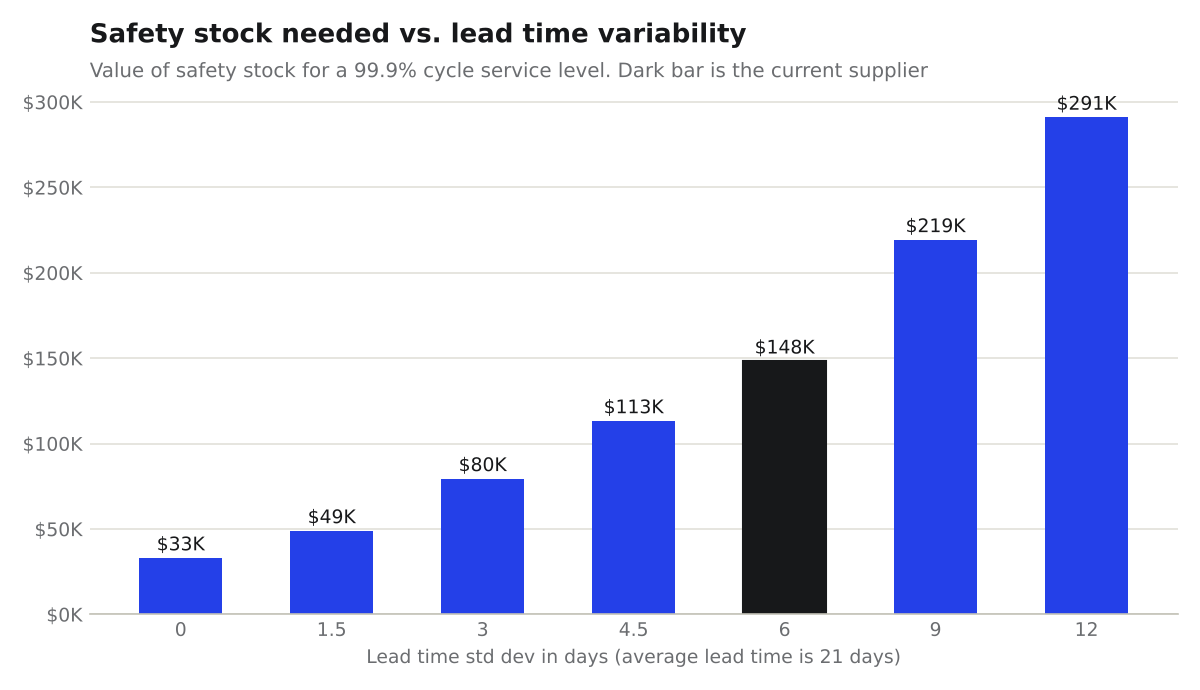

Lead time std dev (days),Safety stock (MCUs),Safety stock value,Total cost / yr,Savings vs current,Break-even price premium
0,"5,098","$33,137","$32,325","$35,606",1.25%
1.5,"7,545","$49,044","$36,627","$31,303",1.10%
3,"12,237","$79,543","$44,935","$22,996",0.81%
4.5,"17,449","$113,416","$56,561","$11,369",0.40%
6,"22,826","$148,371","$67,930",$0,0.00%
9,"33,762","$219,451","$99,235","$-31,304",-1.10%
12,"44,790","$291,138","$136,637","$-68,707",-2.41%


In [6]:
ltv = res["ltv"]
base = ltv.loc[ltv.lead_sd == item.lead_sd].iloc[0]
annual_spend = item.annual_demand * item.unit_cost
ltv_show = ltv[["lead_sd", "safety_stock", "safety_stock_value", "total_cost"]].copy()
ltv_show["Savings vs current"] = base.total_cost - ltv_show.total_cost
ltv_show["Break-even price premium"] = ltv_show["Savings vs current"] / annual_spend
ltv_show.columns = ["Lead time std dev (days)", "Safety stock (MCUs)", "Safety stock value", "Total cost / yr",
                    "Savings vs current", "Break-even price premium"]
display(Image("charts/3_lead_time_variability.png", width=760))
ltv_show.style.format({"Lead time std dev (days)": "{:g}", "Safety stock (MCUs)": "{:,.0f}", "Safety stock value": "${:,.0f}",
                       "Total cost / yr": "${:,.0f}", "Savings vs current": "${:,.0f}",
                       "Break-even price premium": "{:.2%}"}).hide(axis="index")

In [7]:
r3 = ltv.loc[ltv.lead_sd == 3.0].iloc[0]
print(f"Going from a {item.lead_sd:.0f} day to a 3 day lead time std dev:")
print(f"  ${base.safety_stock_value - r3.safety_stock_value:,.0f} less safety stock")
print(f"  ${base.total_cost - r3.total_cost:,.0f}/yr lower total cost")
print(f"  so a distributor like that is worth up to {(base.total_cost - r3.total_cost)/annual_spend:.2%} more per MCU")

Going from a 6 day to a 3 day lead time std dev:
  $68,828 less safety stock
  $22,996/yr lower total cost
  so a distributor like that is worth up to 0.81% more per MCU


This puts a dollar number on delivery reliability, which is something you can actually use when picking a supplier or negotiating. A distributor that cuts its lead time spread in half could charge a little more and still come out cheaper. The same number could back up asking the current distributor for a delivery commitment or a consigned buffer stock.

## The quantity discount
The distributor is offering 3% off every MCU on orders of 25,000 or more (10 full reels).

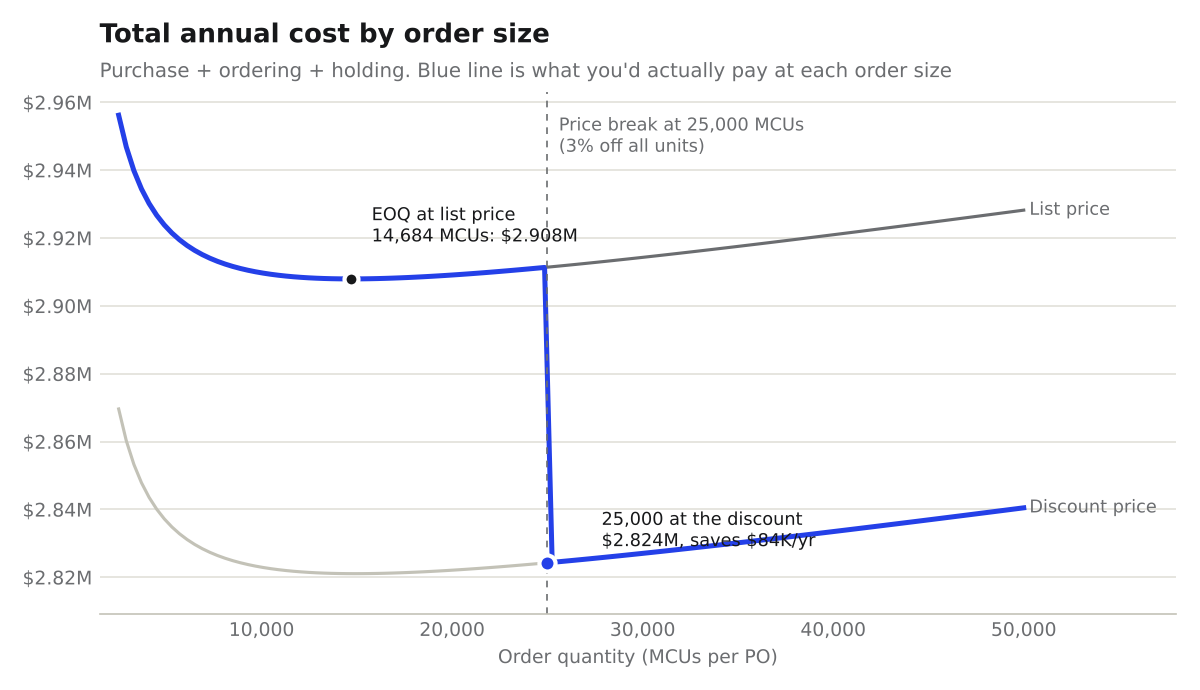

,Order qty,purchase,ordering,cycle_holding,safety_holding,Total
EOQ at list price,"14,684","$2,847,000","$11,931","$11,931","$37,093","$2,907,955"
Order at price break,"25,000","$2,761,590","$7,008","$19,703","$35,980","$2,824,281"


In [8]:
qd = res["qd"]
comp = pd.DataFrame({"EOQ at list price": qd["cost_list"], "Order at price break": qd["cost_disc"]}).T
comp["Total"] = comp.sum(axis=1)
comp.insert(0, "Order qty", [round(qd["q_list"]), round(qd["q_disc"])])
display(Image("charts/4_quantity_discount.png", width=760))
comp.style.format({"Order qty": "{:,.0f}", "purchase": "${:,.0f}", "ordering": "${:,.0f}",
                   "cycle_holding": "${:,.0f}", "safety_holding": "${:,.0f}", "Total": "${:,.0f}"})

In [9]:
extra_wc = (qd["q_disc"] - qd["q_list"]) / 2 * qd["disc_price"]
print(f"Discount saves ${qd['savings']:,.0f}/yr after the extra holding cost")
print(f"but adds about ${extra_wc:,.0f} of average inventory")

Discount saves $83,674/yr after the extra holding cost
but adds about $32,520 of average inventory


The discount is worth it. 3% off the price is worth a lot more than the cost of holding the extra MCUs. Space isn't really an issue since reels are small and stay sealed in moisture barrier bags. The bigger risk is the part going end of life, so I'd check the manufacturer's lifecycle status before committing to bigger buys.

## Where I landed

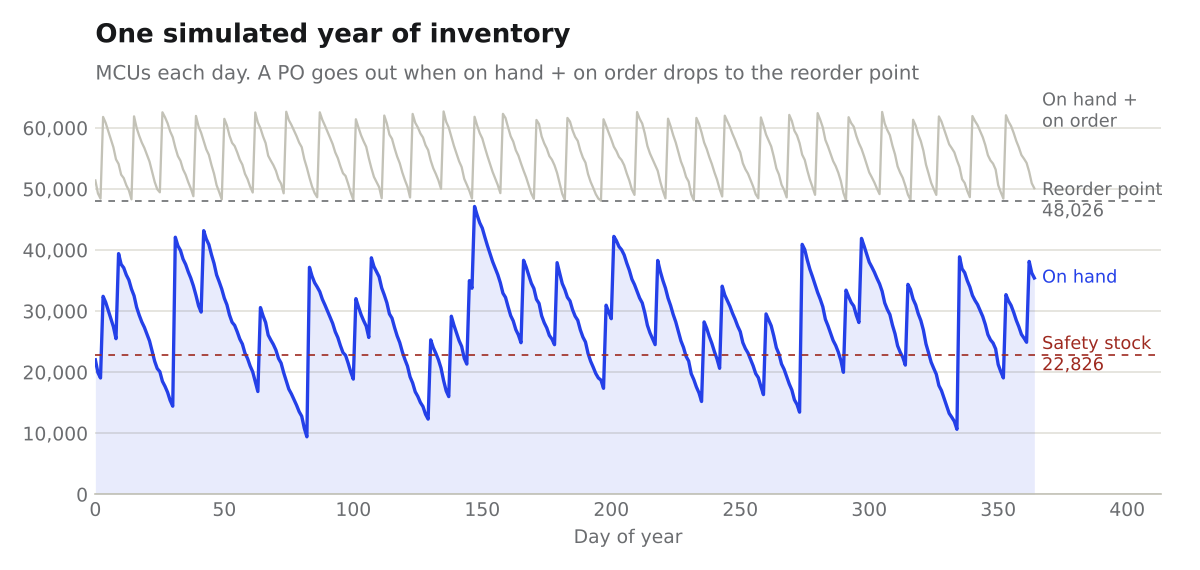

Reorder when on hand + on order drops to 48,026 MCUs (99.9% target)
and order 25,000 MCUs (10 reels) at a time to get the discount.


In [10]:
tr = res["trace"]
display(Image("charts/5_inventory_trace.png", width=760))
s_best = sim.reorder_point(item, float(best.target_csl))
print(f"Reorder when on hand + on order drops to {s_best:,.0f} MCUs ({best.target_csl:.1%} target)")
print(f"and order {qd['q_disc']:,.0f} MCUs (10 reels) at a time to get the discount.")

Overall I'd run a 99.9% target, take the discount, and use the reliability numbers to push the distributor on lead time, since that's where most of the risk is coming from. The code for everything is in inventory_sim.py, and running it directly rebuilds all the charts and results.